# Real vLLM × OpenTelemetry × Prometheus — Interactive Lab

**Built for your working Apple M4 setup.** This notebook uses your **real** vLLM `Qwen/Qwen3-0.6B` server, the OpenTelemetry Collector, and Prometheus. Nothing is simulated.

### Architecture

`Jupyter → concurrent HTTP requests → vLLM (:8000)`

`vLLM /metrics (:8000) ← scraped every 5 seconds by Collector → /metrics (:8889) ← scraped by Prometheus (:9090)`

`Jupyter → Prometheus HTTP query API (:9090) → live charts`

**Important:** the pipeline is currently **Prometheus pull/scraping via an OpenTelemetry Collector**, *not* OTLP push transport. That's a separate next experiment.

### Prerequisites

Keep these processes running in their own Terminal windows: **vLLM**, **otelcol-contrib**, **Prometheus**. These notebook cells connect only to `127.0.0.1` and do not change any iCloud settings. Stop any test cell with **Kernel → Interrupt Kernel** if needed.

**Run cells from top to bottom with `Shift + Return`.** The default test is intentionally small: **6 requests, concurrency 2, 32 output tokens/request**. The vLLM server was started with `--max-num-seqs 1`, so simultaneous HTTP requests should cause some queueing.

## 1. Connect to the three running services

We use Python's standard library for HTTP requests; only the charts need `matplotlib`.

In [1]:
import json
import math
import time
import urllib.parse
import urllib.request
import urllib.error
from concurrent.futures import ThreadPoolExecutor
from IPython.display import clear_output, display
import matplotlib.pyplot as plt

VLLM = "http://127.0.0.1:8000"
COLLECTOR = "http://127.0.0.1:8889"
PROMETHEUS = "http://127.0.0.1:9090"


def http_json(url, payload=None, timeout=15):
    body = json.dumps(payload).encode("utf-8") if payload is not None else None
    headers = {"Content-Type": "application/json"} if payload is not None else {}
    req = urllib.request.Request(url, data=body, headers=headers)
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


def prom_query(expression):
    url = PROMETHEUS + "/api/v1/query?" + urllib.parse.urlencode({"query": expression})
    data = http_json(url)
    if data.get("status") != "success":
        raise RuntimeError(f"Prometheus query failed: {data}")
    return data["data"]["result"]


def prom_scalar(expression):
    series = prom_query(expression)
    if not series:
        return math.nan
    return float(series[0]["value"][1])

try:
    models = http_json(VLLM + "/v1/models")["data"]
    MODEL = models[0]["id"]
    print("vLLM model:", MODEL)
    print("Prometheus collector target UP:", prom_scalar('up{job="otel_collector"}'))
    print("Collector /metrics HTTP:", urllib.request.urlopen(COLLECTOR + "/metrics", timeout=10).status)
except Exception as error:
    print("A local service is not reachable:", repr(error))
    print("Check that vLLM (8000), Collector (8889), and Prometheus (9090) are still running.")
    raise

Matplotlib is building the font cache; this may take a moment.


vLLM model: Qwen/Qwen3-0.6B
Prometheus collector target UP: 1.0
Collector /metrics HTTP: 200


## 2. Run several PromQL expressions together

Prometheus stores time series. A query through `/api/v1/query` returns a snapshot. **`up=1`** means Prometheus can scrape the Collector; it does not independently prove the model is healthy.

The token counters include your earlier request, so the starting values will not necessarily be zero.

In [2]:
QUERIES = {
    "Collector target UP": 'up{job="otel_collector"}',
    "Requests completed": 'sum(vllm:request_success_total)',
    "Prompt tokens": 'sum(vllm:prompt_tokens_total)',
    "Generation tokens": 'sum(vllm:generation_tokens_total)',
    "Requests running": 'sum(vllm:num_requests_running)',
    "Requests waiting": 'sum(vllm:num_requests_waiting)',
    "KV cache usage (fraction)": 'avg(vllm:kv_cache_usage_perc)',
    "Output tokens / sec, 1m rate": 'sum(rate(vllm:generation_tokens_total[1m]))',
}

for label, expression in QUERIES.items():
    try:
        value = prom_scalar(expression)
        print(f"{label:32} {value:10.4f}  |  {expression}")
    except Exception as exc:
        print(label, "ERROR:", exc)

Collector target UP                  1.0000  |  up{job="otel_collector"}
Requests completed                   6.0000  |  sum(vllm:request_success_total)
Prompt tokens                       93.0000  |  sum(vllm:prompt_tokens_total)
Generation tokens                  288.0000  |  sum(vllm:generation_tokens_total)
Requests running                     0.0000  |  sum(vllm:num_requests_running)
Requests waiting                     0.0000  |  sum(vllm:num_requests_waiting)
KV cache usage (fraction)            0.0000  |  avg(vllm:kv_cache_usage_perc)
Output tokens / sec, 1m rate         0.0000  |  sum(rate(vllm:generation_tokens_total[1m]))


## 3. Ask the model something yourself

This request is for experimenting with model behavior. **Qwen3 may emit `<think>` text and exhaust small token limits**: `finish_reason="length"` means the generation hit the cap, not that your HTTP request failed.

In [3]:
MY_PROMPT = "Explain the difference between GPU prefill and decode in two simple sentences."

response = http_json(VLLM + "/v1/chat/completions", {
    "model": MODEL,
    "messages": [{"role": "user", "content": MY_PROMPT}],
    "max_tokens": 96,
    "temperature": 0,
}, timeout=120)
print("Model output:\n", response["choices"][0]["message"]["content"])
print("\nUsage:", response.get("usage"))
print("Finish reason:", response["choices"][0].get("finish_reason"))

Model output:
 <think>
Okay, the user wants to know the difference between GPU prefill and decode in two simple sentences. Let me start by recalling what each term means. GPU prefill is when the GPU preloads data before processing, right? So maybe it's like loading data into the GPU before the actual computation starts. Then decode would be when the GPU processes the data, maybe converting it into something else like a video stream or image. I need to make sure these two are distinct

Usage: {'prompt_tokens': 23, 'total_tokens': 119, 'completion_tokens': 96, 'prompt_tokens_details': None, 'completion_tokens_details': None}
Finish reason: length


## 4. Start concurrent HTTP requests in the background

**This is the part you asked for:** start multiple requests, *return immediately*, and use the next cell to graph metrics while requests are still executing.

Default: **6 requests**, **2 concurrent workers**, **32 tokens per response**. Your server's `--max-num-seqs 1` means it executes one sequence at a time, so *waiting requests may appear*. With very short requests or five-second scrapes you might miss brief queue spikes—this is normal.

Re-run this cell with a larger `REQUESTS` (up to 20) only after the first batch works.

In [27]:
REQUESTS = 12
CONCURRENCY = 1
TOKENS_PER_REQUEST = 128

LOAD_FUTURES = []
LOAD_EXECUTOR = None


def one_inference(index, max_tokens):
    started = time.monotonic()
    try:
        result = http_json(VLLM + "/v1/chat/completions", {
            "model": MODEL,
            "messages": [{"role": "user", "content": f"Request {index}: give one tip for GPU inference performance."}],
            "max_tokens": max_tokens,
            "temperature": 0,
        }, timeout=120)
        usage = result.get("usage") or {}
        return {
            "request": index,
            "seconds": round(time.monotonic() - started, 2),
            "prompt_tokens": usage.get("prompt_tokens"),
            "generation_tokens": usage.get("completion_tokens"),
            "finish_reason": result["choices"][0].get("finish_reason"),
            "status": "OK",
        }
    except Exception as exc:
        return {"request": index, "seconds": round(time.monotonic()-started, 2),
                "status": "ERROR", "error": str(exc)}


def start_load(requests=6, concurrency=2, tokens=32):
    global LOAD_FUTURES, LOAD_EXECUTOR
    if any(not f.done() for f in LOAD_FUTURES):
        raise RuntimeError("An earlier load test is still running.")
    if not (1 <= requests <= 20 and 1 <= concurrency <= 3 and 1 <= tokens <= 128):
        raise ValueError("Safety limits: 1-20 requests, 1-3 concurrency, 1-128 tokens.")
    if LOAD_EXECUTOR is not None:
        LOAD_EXECUTOR.shutdown(wait=True)
    LOAD_EXECUTOR = ThreadPoolExecutor(max_workers=concurrency)
    LOAD_FUTURES = [LOAD_EXECUTOR.submit(one_inference, i, tokens)
                    for i in range(1, requests+1)]
    print(f"Started {requests} requests, concurrency={concurrency}, max_tokens={tokens}.")
    print("Immediately run the NEXT cell to watch the live metrics.")

start_load(REQUESTS, CONCURRENCY, TOKENS_PER_REQUEST)

Started 12 requests, concurrency=1, max_tokens=128.
Immediately run the NEXT cell to watch the live metrics.


## 5. LIVE metrics dashboard — run immediately after starting load

This cell asks Prometheus for the latest metrics every **3 seconds**. Because the Collector and Prometheus both scrape every **5 seconds**, the plotted values update in steps; it isn't a direct stream from the model.

Watch how **running**, **waiting**, **token counters**, **token throughput**, and **KV-cache utilization** change. Default dashboard runtime is **90 seconds**. You can interrupt at any point from the notebook toolbar. The load-test threads already running may continue until their requests finish.

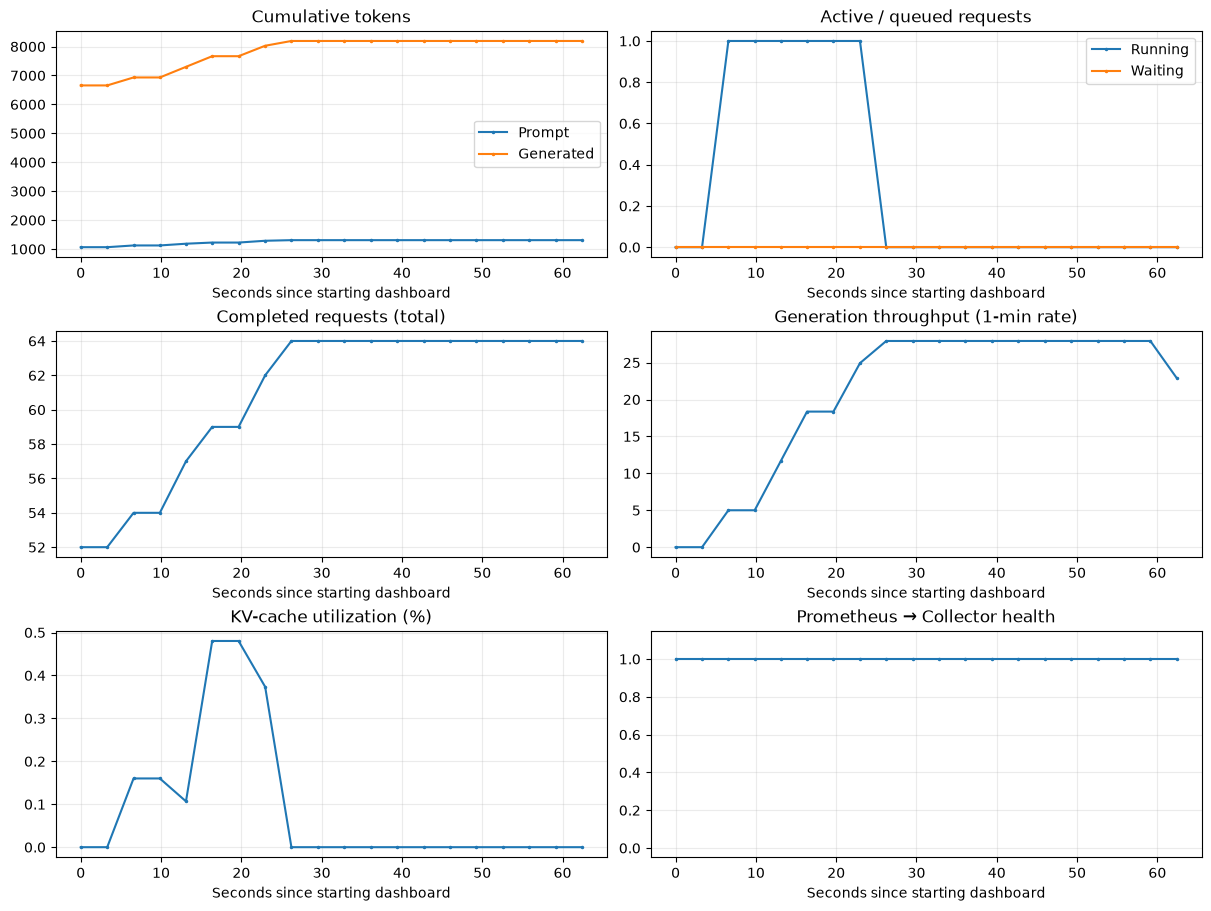

Elapsed: 62s / 90s | Background requests completed: 12/12
Scraping is periodic: repeated or stair-step values are expected.


KeyboardInterrupt: 

In [28]:
DASHBOARD_SECONDS = 90
POLL_SECONDS = 3

PANEL_QUERIES = {
    "up": 'up{job="otel_collector"}',
    "requests": 'sum(vllm:request_success_total)',
    "input": 'sum(vllm:prompt_tokens_total)',
    "output": 'sum(vllm:generation_tokens_total)',
    "running": 'sum(vllm:num_requests_running)',
    "waiting": 'sum(vllm:num_requests_waiting)',
    "tokens_s": 'sum(rate(vllm:generation_tokens_total[1m]))',
    "kv_pct": 'avg(vllm:kv_cache_usage_perc)*100',
}

history = {key: [] for key in PANEL_QUERIES}
elapsed = []
start = time.monotonic()

while True:
    elapsed.append(time.monotonic() - start)
    for name, expression in PANEL_QUERIES.items():
        try:
            history[name].append(prom_scalar(expression))
        except Exception:
            history[name].append(math.nan)

    fig, axes = plt.subplots(3, 2, figsize=(12, 9), constrained_layout=True)
    specs = [
        (axes[0, 0], [("input", "Prompt"), ("output", "Generated")], "Cumulative tokens"),
        (axes[0, 1], [("running", "Running"), ("waiting", "Waiting")], "Active / queued requests"),
        (axes[1, 0], [("requests", "Completed")], "Completed requests (total)"),
        (axes[1, 1], [("tokens_s", "Tokens/s")], "Generation throughput (1-min rate)"),
        (axes[2, 0], [("kv_pct", "KV %")], "KV-cache utilization (%)"),
        (axes[2, 1], [("up", "Collector UP")], "Prometheus → Collector health"),
    ]
    for ax, plotted, title in specs:
        for key, legend in plotted:
            ax.plot(elapsed, history[key], label=legend, marker=".", markersize=3)
        ax.set_title(title)
        ax.set_xlabel("Seconds since starting dashboard")
        ax.grid(alpha=0.25)
        if len(plotted) > 1:
            ax.legend(loc="best")
    axes[2, 1].set_ylim(-0.05, 1.15)
    clear_output(wait=True)
    display(fig)
    plt.close(fig)
    finished = sum(f.done() for f in LOAD_FUTURES)
    print(f"Elapsed: {elapsed[-1]:.0f}s / {DASHBOARD_SECONDS}s | Background requests completed: {finished}/{len(LOAD_FUTURES)}")
    print("Scraping is periodic: repeated or stair-step values are expected.")
    if elapsed[-1] >= DASHBOARD_SECONDS:
        break
    time.sleep(POLL_SECONDS)

print("Dashboard finished. You can start a new load test or run the next cell.")

## 6. Inspect individual request results

These per-request values come from the HTTP responses, while the graphs come from **aggregate server metrics** in Prometheus. They answer different questions.

In [18]:
if not LOAD_FUTURES:
    print("No load test has been started.")
else:
    for future in LOAD_FUTURES:
        if future.done():
            print(future.result())
        else:
            print("Still running...")

{'request': 1, 'seconds': 2.6, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 2, 'seconds': 2.58, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 3, 'seconds': 4.33, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 4, 'seconds': 1.77, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 5, 'seconds': 3.46, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 6, 'seconds': 1.76, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 7, 'seconds': 3.46, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 8, 'seconds': 1.75, 'prompt_tokens': 20, 'generation_tokens': 128, 'finish_reason': 'length', 'status': 'OK'}
{'request': 9, 'seconds':

## 7. Run your own PromQL expression

Try queries one at a time, or edit the list to evaluate several in the same cell.

Example questions:

- How many successful completions were cut off by the token limit?
- How many tokens/second are we generating lately?
- Did the Collector stay up?
- How many requests were waiting?

You may see multiple results for the grouped finish reasons.

In [19]:
MY_PROMQL = [
    'sum by (finished_reason) (vllm:request_success_total)',
    'sum(rate(vllm:generation_tokens_total[1m]))',
    'sum(vllm:num_requests_waiting)',
    'up{job="otel_collector"}',
]

for expr in MY_PROMQL:
    print("\nQUERY:", expr)
    for series in prom_query(expr):
        labels = series.get("metric", {})
        print("  labels=", labels, " value=", series.get("value", [None, None])[1])


QUERY: sum by (finished_reason) (vllm:request_success_total)
  labels= {'finished_reason': 'abort'}  value= 0
  labels= {'finished_reason': 'error'}  value= 0
  labels= {'finished_reason': 'length'}  value= 32
  labels= {'finished_reason': 'repetition'}  value= 0
  labels= {'finished_reason': 'stop'}  value= 0

QUERY: sum(rate(vllm:generation_tokens_total[1m]))
  labels= {}  value= 0

QUERY: sum(vllm:num_requests_waiting)
  labels= {}  value= 0

QUERY: up{job="otel_collector"}
  labels= {'__name__': 'up', 'exported_instance': '127.0.0.1:8000', 'exported_job': 'vllm_local', 'instance': '127.0.0.1:8889', 'job': 'otel_collector', 'otel_scope_name': 'github.com/open-telemetry/opentelemetry-collector-contrib/receiver/prometheusreceiver', 'otel_scope_version': '0.162.0'}  value= 1
  labels= {'__name__': 'up', 'instance': '127.0.0.1:8889', 'job': 'otel_collector'}  value= 1


## 8. Explore history with `/api/v1/query_range`

An **instant** query (`/query`) shows a value at one instant. A **range** query (`/query_range`) returns historical samples and lets us graph the pattern later. This cell uses Prometheus's built-in query API without needing Grafana.

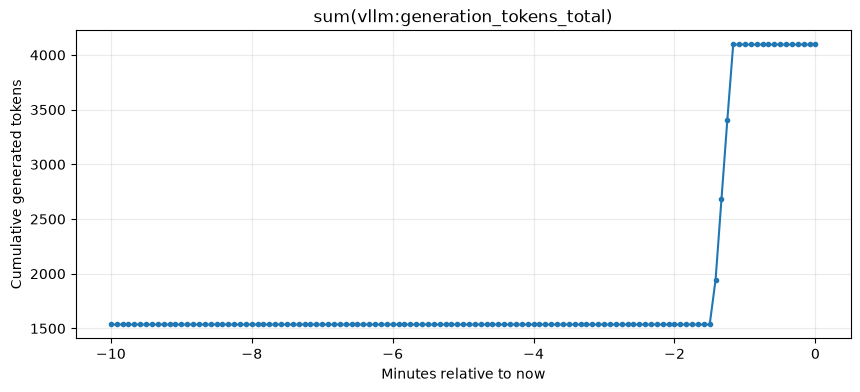

In [20]:
def prom_range(expression, minutes=10, step=5):
    end = time.time()
    params = {"query": expression, "start": end - minutes * 60, "end": end, "step": step}
    url = PROMETHEUS + "/api/v1/query_range?" + urllib.parse.urlencode(params)
    response = http_json(url, timeout=15)
    if response.get("status") != "success":
        raise RuntimeError(response)
    return response["data"]["result"]

expression = 'sum(vllm:generation_tokens_total)'
series = prom_range(expression, minutes=10, step=5)
if not series:
    print("No points available yet. Let Prometheus scrape a few more times.")
else:
    timestamps, values = zip(*[(float(t), float(v)) for t, v in series[0]["values"]])
    minutes_ago = [(t - timestamps[-1]) / 60 for t in timestamps]
    plt.figure(figsize=(10, 4))
    plt.plot(minutes_ago, values, marker=".")
    plt.xlabel("Minutes relative to now")
    plt.ylabel("Cumulative generated tokens")
    plt.title(expression)
    plt.grid(alpha=0.25)
    plt.show()

## 9. Learn the inference performance metrics

| Measurement | PromQL / meaning | Interpret carefully |
|---|---|---|
| **Throughput** | `sum(rate(vllm:generation_tokens_total[1m]))` | Aggregate generated tokens per second over the last minute, **not per-request decode speed** |
| **Queueing** | `sum(vllm:num_requests_waiting)` | A gauge; may be missed if requests finish between scrapes |
| **Running** | `sum(vllm:num_requests_running)` | Current active sequences during a scrape |
| **KV cache** | `avg(vllm:kv_cache_usage_perc)` | Fraction of cache in use (0–1) |
| **Finish reasons** | `sum by(finished_reason) (vllm:request_success_total)` | `length` = token cap; not a complete natural stop |
| **TTFT mean** | Histogram `sum(rate(..._sum[5m])) / sum(rate(..._count[5m]))` | Estimate across recent requests; empty if no recent data |
| **E2E latency** | `vllm:e2e_request_latency_seconds_bucket` | Cumulative histogram; latency buckets, not individual latencies |

### Try one end-to-end latency query

If you only have a handful of requests, the 5-minute window may produce `NaN` when no new requests occur. That is expected.

In [31]:
LATENCY_PROMQL = (
    'sum(rate(vllm:e2e_request_latency_seconds_sum[5m])) / '
    'sum(rate(vllm:e2e_request_latency_seconds_count[5m]))'
)
print("Mean end-to-end latency over active samples (s):", prom_scalar(LATENCY_PROMQL))

TTFT_PROMQL = (
    'sum(rate(vllm:time_to_first_token_seconds_sum[5m])) / '
    'sum(rate(vllm:time_to_first_token_seconds_count[5m]))'
)
print("Mean TTFT over active samples (s):", prom_scalar(TTFT_PROMQL))

Mean end-to-end latency over active samples (s): 2.333320587873459
Mean TTFT over active samples (s): 0.6139813885092735


## 10. Things to try next (in order)

1. Run **6 requests with concurrency=1**, record generated tokens/s.
2. Run **6 requests with concurrency=2**, compare waiting requests and throughput. Your vLLM server has `--max-num-seqs 1`, so don't expect parallel model execution.
3. Double the prompt length. Compare prompt tokens and end-to-end latency.
4. Increase the generation token limit carefully (e.g., 32 → 64), compare token totals and duration.
5. Stop and restart the Collector while Prometheus stays up. Watch `up{job="otel_collector"}` move to 0 then back to 1 (after the scrape intervals). **Do not stop your friend's unrelated services.**
6. Separately configure the OTLP receiver and export traces. **This current notebook uses Prometheus-format scraping, not OTLP push transport.**

### Cleanup

- Notebook: in JupyterLab choose **Kernel → Shut Down Kernel**, then stop the `jupyter lab` command with `Control + C`.
- The vLLM, Collector, and Prometheus processes remain in their own Terminals unless you stop them separately.
- Notebook file and charts stay in `~/Pranav-vLLM-Lab/`, outside the iCloud Drive Documents folder.